# TP3 - CNN´s en Imagenes Satelitales

> Utilizaremos el dataset EuroSAT para entrenar un modelo de redes neuronales convulacionales. La idea principal es identifiar distintos tipos del uso del suelo vía imagenes.

> Para crear el modelo de CNN´s utilizaremos la biblioteca *PyTorch*. Esta biblioteca es de aprendizaje automatico y deep learning. Podemos crear tensores, diferenciación automatica y construir redes neuronales.

**Descripción del dataset.** EuroSAT contiene imágenes satelitales del satélite Sentinel-2 (versión RGB).
Cada imagen tiene 64 × 64 píxeles y cada píxel cubre 10 m × 10 m de terreno, por lo que una imagen
representa un área de 640 m × 640 m. Hay 10 clases de uso del suelo:

| Clase | Descripción |
|---|---|
| AnnualCrop | Cultivos que se siembran y cosechan cada año (parcelas rectangulares) |
| PermanentCrop | Cultivos permanentes: viñedos, frutales, olivares |
| Pasture | Pasturas para ganado |
| HerbaceousVegetation | Vegetación herbácea natural, sin uso agrícola |
| Forest | Bosques |
| Highway | Rutas y autopistas |
| Industrial | Zonas industriales y comerciales |
| Residential | Zonas residenciales |
| River | Ríos |
| SeaLake | Mar y lagos |


In [88]:
# Bibliotecas

import pandas as pd
import torch
import matplotlib.pyplot as plt 
from torchvision import transforms

DATA_DIR = "EuroSAT" # Directorio donde se encuentran los datos.

#### 1- Analizamos un análisis explotario de los datos (EDA). 

> Lo realizamos para mirar y entender los datos antes de modelar. Sin entrenar podemos hacernos preguntas sobre el dataset. 

> Podemos detectar problemas antes de entrenar, tomar decisiones de preprocesamiento y anticipar resultados.

In [89]:
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
validation_df = pd.read_csv(f"{DATA_DIR}/validation.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

In [90]:
train_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,16257,AnnualCrop/AnnualCrop_142.jpg,0,AnnualCrop
1,3297,HerbaceousVegetation/HerbaceousVegetation_2835...,2,HerbaceousVegetation
2,17881,PermanentCrop/PermanentCrop_1073.jpg,6,PermanentCrop
3,2223,Industrial/Industrial_453.jpg,4,Industrial
4,4887,HerbaceousVegetation/HerbaceousVegetation_1810...,2,HerbaceousVegetation


In [91]:
validation_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,258,Pasture/Pasture_1481.jpg,5,Pasture
1,2134,Forest/Forest_2638.jpg,1,Forest
2,3518,Highway/Highway_875.jpg,3,Highway
3,3048,River/River_434.jpg,8,River
4,3996,SeaLake/SeaLake_2930.jpg,9,SeaLake


In [92]:
test_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,2438,AnnualCrop/AnnualCrop_1275.jpg,0,AnnualCrop
1,1018,Residential/Residential_504.jpg,7,Residential
2,3,Pasture/Pasture_787.jpg,5,Pasture
3,1011,Residential/Residential_1575.jpg,7,Residential
4,47,Pasture/Pasture_473.jpg,5,Pasture


In [93]:
# Limpieza de datos:
# Descartamos la primera columna que no aporta valor alguno. Solamente es el indice que tenia en la fila en el dataset original.

test_df = test_df.drop(columns=["Unnamed: 0"])

validation_df = validation_df.drop(columns=["Unnamed: 0"])

train_df = train_df.drop(columns=["Unnamed: 0"])

In [94]:
# Tamaño de los datasets:

test_df.shape[0]

2700

In [95]:
validation_df.shape[0]

5400

In [96]:
train_df.shape[0]

18900

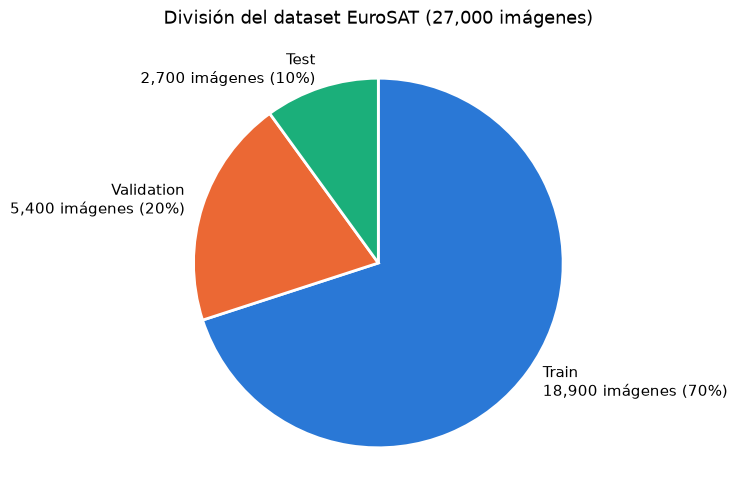

In [97]:
import matplotlib.pyplot as plt

# 1) Datos: nombre y cantidad de imágenes de cada split
nombres = ["Train", "Validation", "Test"]
tamaños = [len(train_df), len(validation_df), len(test_df)]  # len() = cantidad de filas
total = sum(tamaños)

# 2) Etiquetas con nombre, cantidad y porcentaje
etiquetas = [
    f"{nombre}\n{tamaño:,} imágenes ({tamaño / total:.0%})"
    for nombre, tamaño in zip(nombres, tamaños)
]

# 3) Gráfico de torta
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    tamaños,
    labels=etiquetas,
    colors=["#2a78d6", "#eb6834", "#1baf7a"],     # un color distinto por split
    startangle=90,                                # arranca desde arriba
    counterclock=False,                           # gira en sentido horario
    wedgeprops={"edgecolor": "white", "linewidth": 2},  # separa las porciones
    textprops={"fontsize": 11},
)
ax.set_title(f"División del dataset EuroSAT ({total:,} imágenes)", fontsize=13)
plt.show()


> Como vemos, la división de datasets esta en formato estandar de simple holdout set + validation y tenemos imagenes de mas como para entrenar, validar y testear el modelo.

> **¿Las clases estan balanceadas?**


In [98]:
# Cantidad de imágenes por clase en cada split
conteos = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(),
    "Validation": validation_df["ClassName"].value_counts(),
    "Test": test_df["ClassName"].value_counts(),
})

# Proporción de cada clase dentro de su split (cada columna suma 1)
proporciones = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(normalize=True),
    "Validation": validation_df["ClassName"].value_counts(normalize=True),
    "Test": test_df["ClassName"].value_counts(normalize=True),
})

# Ordenamos de mayor a menor según train
orden = conteos["Train"].sort_values(ascending=False).index
conteos = conteos.loc[orden]
proporciones = proporciones.loc[orden]

print("Cantidad de imágenes por clase:")
print(conteos)
print("\nProporción de cada clase por split (%):")
print((proporciones * 100).round(1))


Cantidad de imágenes por clase:
                      Train  Validation  Test
ClassName                                    
AnnualCrop             2100         600   300
Forest                 2100         600   300
HerbaceousVegetation   2100         600   300
Residential            2100         600   300
SeaLake                2100         600   300
Highway                1750         500   250
PermanentCrop          1750         500   250
Industrial             1750         500   250
River                  1750         500   250
Pasture                1400         400   200

Proporción de cada clase por split (%):
                      Train  Validation  Test
ClassName                                    
AnnualCrop             11.1        11.1  11.1
Forest                 11.1        11.1  11.1
HerbaceousVegetation   11.1        11.1  11.1
Residential            11.1        11.1  11.1
SeaLake                11.1        11.1  11.1
Highway                 9.3         9.3   9.3
Permane

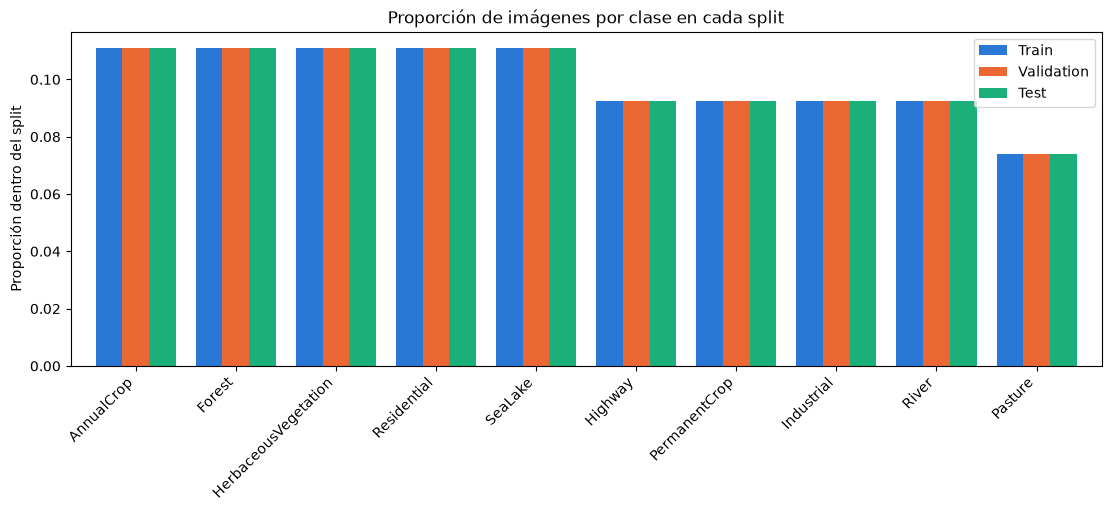

In [99]:
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
proporciones.plot.bar(ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.8)
ax.set_title("Proporción de imágenes por clase en cada split")
ax.set_xlabel("")
ax.set_ylabel("Proporción dentro del split")
plt.xticks(rotation=45, ha="right")
plt.show()


> Como vemos en las tablas y el gráfico generado, las clases estan bien balanceadas por ClassName. La unica clase que tiene un poco menos de imagenes es Pasture. Pero es un desbalance leve.

> También, vemos que por cada split se entrenara la misma proporción de clases.

> Podemos realizar data augmentation para que en las clases con desbalances para que el modelo generalice mejor.

> Como hay un desbalance leve, accuracy es una métrica que podemos utilizar y sera valida.

> **¿Hay imagenes duplicadas?**


In [100]:
# Juntamos los tres splits para chequear duplicados entre ellos
todos_df = pd.concat([train_df, validation_df, test_df])

# ¿Alguna imagen aparece más de una vez (dentro de un split o en dos splits distintos)?
print(f"Filas totales: {len(todos_df)}")
print(f"Archivos repetidos: {todos_df['Filename'].duplicated().sum()}")

# ¿La clase de cada fila coincide con la carpeta donde está la imagen?
carpeta = todos_df["Filename"].str.split("/").str[0]
print(f"Filas donde la carpeta no coincide con ClassName: {(carpeta != todos_df['ClassName']).sum()}")

# ¿Cada clase tiene un único Label numérico?
print(todos_df.groupby("ClassName")["Label"].unique())


Filas totales: 27000
Archivos repetidos: 0
Filas donde la carpeta no coincide con ClassName: 0
ClassName
AnnualCrop              [0]
Forest                  [1]
HerbaceousVegetation    [2]
Highway                 [3]
Industrial              [4]
Pasture                 [5]
PermanentCrop           [6]
Residential             [7]
River                   [8]
SeaLake                 [9]
Name: Label, dtype: object


> En el resultado vemos que no hay imagenes repetidas entre los datasets train, validation y test. 

> Si hubiera imagenes en train y en test iguales, estariamos ante un caso de data leakage. 

> **¿A que tipo de imagenes nos enfrentamos? ¿Cuales se parecen?**

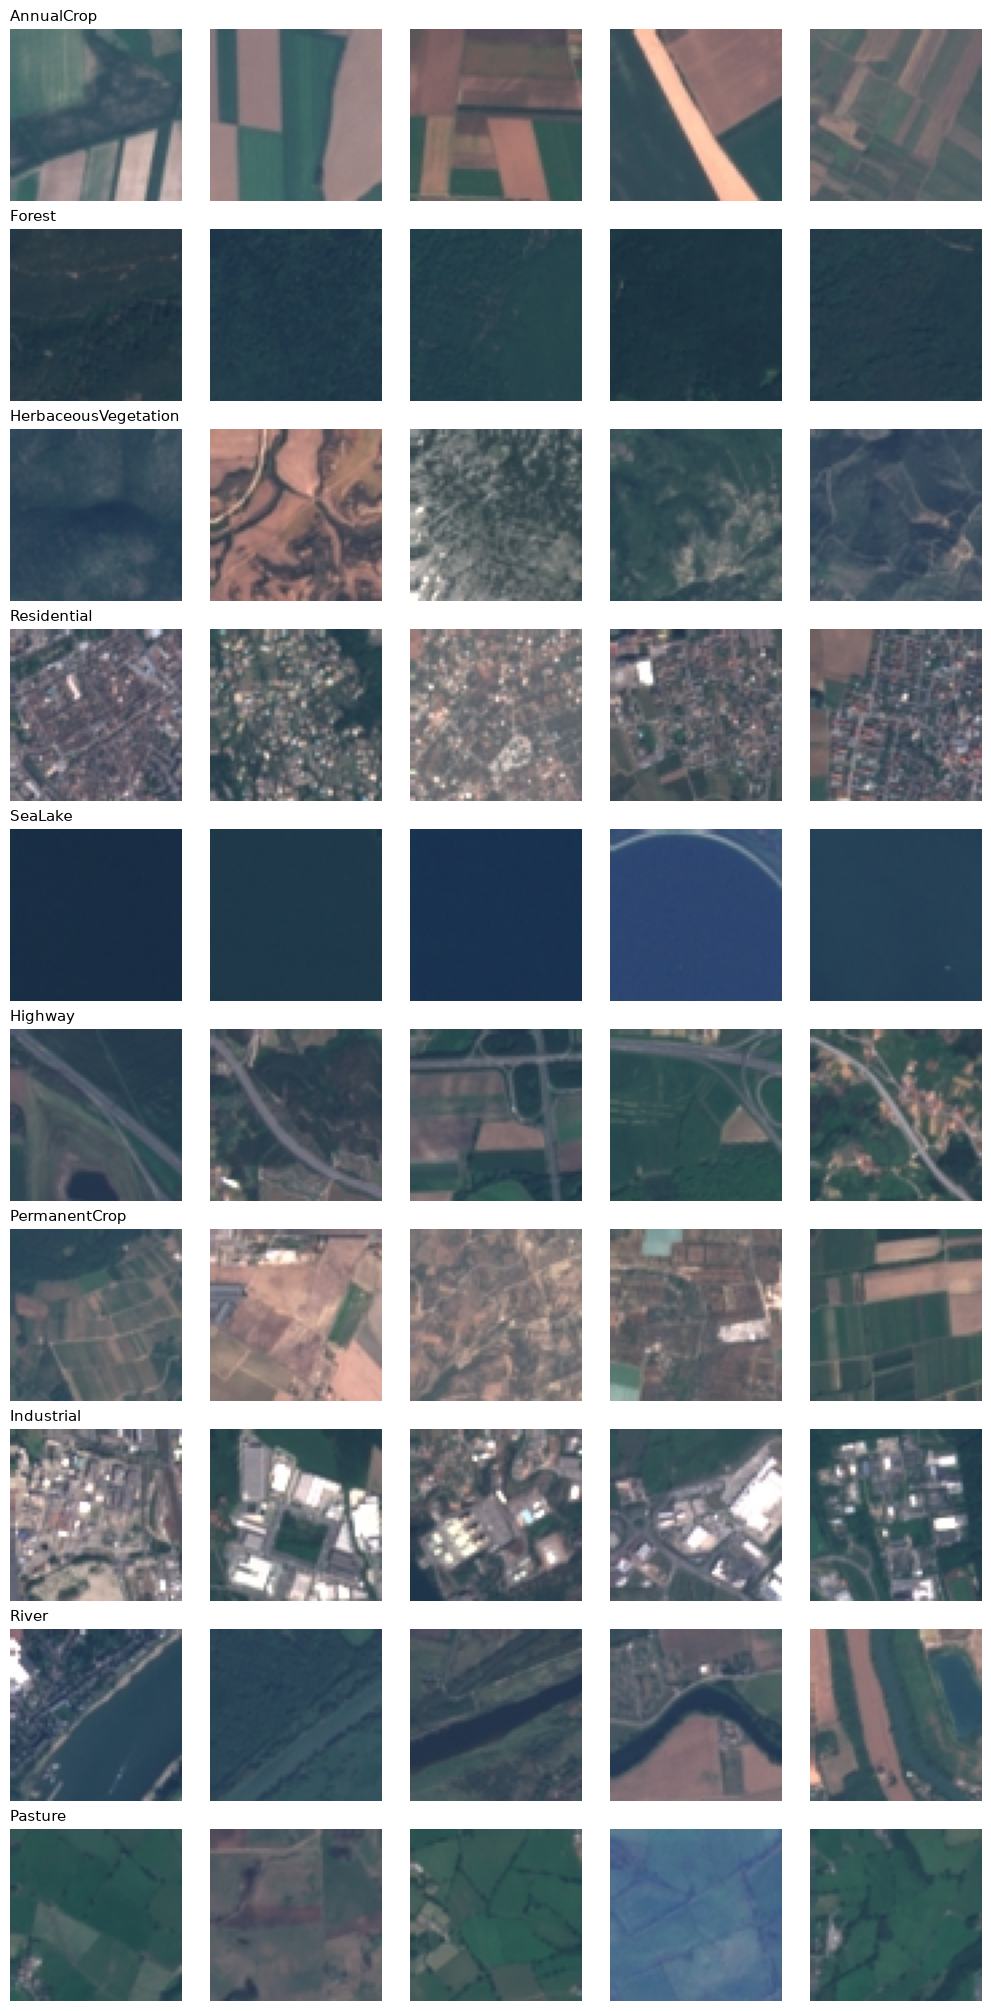

In [101]:
# Mostramos 5 imágenes de cada clase (mismo esquema que la grilla de MNIST de la Práctica 13)
n_ejemplos = 5
fig, axs = plt.subplots(len(orden), n_ejemplos, figsize=(10, 20), constrained_layout=True)

for i, clase in enumerate(orden):
    # Filtramos las imágenes de esta clase y tomamos 5 al azar (random_state para reproducibilidad)
    ejemplos = train_df[train_df["ClassName"] == clase].sample(n_ejemplos, random_state=42)

    for j, archivo in enumerate(ejemplos["Filename"]):
        imagen = plt.imread(f"{DATA_DIR}/{archivo}")  # lee el .jpg como array (64, 64, 3)
        axs[i, j].imshow(imagen)
        axs[i, j].axis("off")

    axs[i, 0].set_title(clase, loc="left", fontsize=11)

plt.show()


> Vemos que para algunos casos las imagenes se parecen mucho: Pasture vs HerbaceousVegetation (los dos son verde claro sin estructura). AnnualCrop vs PermanentCrop (los dos son parcelas agrícolas). Highway vs River (los dos son una línea que cruza la imagen). Industrial vs Residential (los dos son construcciones). SeaLake vs Forest (los dos son solamente de un color). 

> Lo tenemos en cuenta para el modelado y para despues entender los resultados.

> **Cargamos las imagenes en tensores.**

In [102]:
# Leemos cada imagen de train y la pasamos a tensor
lista_imagenes = [torch.from_numpy(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in train_df["Filename"]]

# Apilamos todas en un solo tensor: (cantidad, alto, ancho, canales)
imagenes_train = torch.stack(lista_imagenes, dim=0)

# Aplanamos cada imagen a un vector de 64*64*3 y contamos cuántas filas distintas hay
imagenes_unicas = torch.unique(imagenes_train.view(len(imagenes_train), -1), dim=0)
print(f"Imágenes con contenido distinto: {len(imagenes_unicas)} de {len(imagenes_train)}")

print(f"Forma del tensor: {imagenes_train.shape}")
print(f"Tipo de dato: {imagenes_train.dtype}")
print(f"Valor mínimo: {imagenes_train.min()}, valor máximo: {imagenes_train.max()}")


Imágenes con contenido distinto: 18900 de 18900
Forma del tensor: torch.Size([18900, 64, 64, 3])
Tipo de dato: torch.uint8
Valor mínimo: 0, valor máximo: 255


> Cada imagen es un tensor de 3 dimensiones: alto × ancho × canales. Los canales son los 3 colores RGB (red, green, blue), y cada píxel tiene un valor entre 0 y 255 por canal.

> Vemos también que no hay imagenes con contenido igual cuando los convertimos a los tensores. Al no haber filas iguales en los tensores, hay independencia lineal entre ellas.

In [103]:
# Escalamos a [0, 1]: pasamos a float y dividimos por 255
imagenes_train = imagenes_train.float() / 255

# Media y desvío por canal: reducimos sobre imágenes, alto y ancho (dims 0, 1, 2) y queda solo el canal
media = torch.mean(imagenes_train, dim=(0, 1, 2))
desvio = torch.std(imagenes_train, dim=(0, 1, 2))

print(f"Media por canal (R, G, B): {media}")
print(f"Desvío por canal (R, G, B): {desvio}")


Media por canal (R, G, B): tensor([0.3445, 0.3803, 0.4078])
Desvío por canal (R, G, B): tensor([0.2031, 0.1371, 0.1157])


> Normalizamos igual que con StandardScaler en ML. Queremos que los tensores esten centrados en 0 y con std de 1. 

> Primero, escalamos entre [0,1] diviendo entre 255.

| Canal | Media | Desvío |
|---|---|---|
| R (rojo) | 0.3445 | 0.2031 |
| G (verde) | 0.3803 | 0.1371 |
| B (azul) | 0.4078 | 0.1157 |

> Vemos que todas las medias estan debajo de 0,5. Significa que son imagenes en promedio bastante oscuras.

> El canal azul tiene la media más grande. Puede ser que por los Rivers o por los SeaLake que tienen tonos oscuros de colores parecidos al azul.

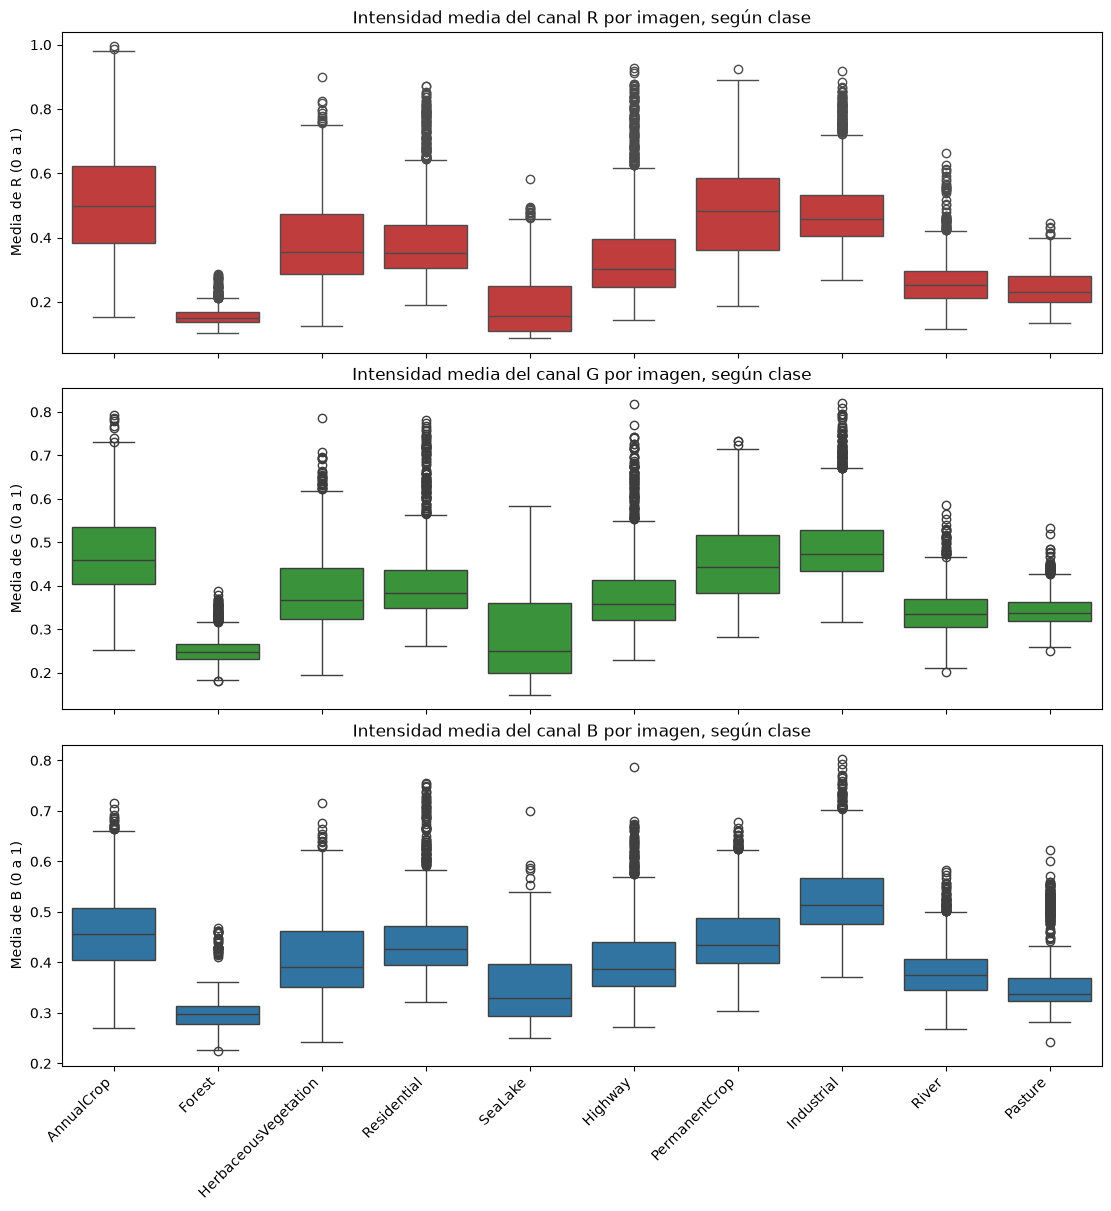

In [104]:
import seaborn as sns

# Color promedio de cada imagen: promediamos alto y ancho (dims 1, 2) → (18900, 3)
color_por_imagen = torch.mean(imagenes_train, dim=(1, 2))

color_df = pd.DataFrame(color_por_imagen.numpy(), columns=["R", "G", "B"])
color_df["ClassName"] = train_df["ClassName"].values  # mismo orden en que cargamos las imágenes

fig, axs = plt.subplots(3, 1, figsize=(11, 12), constrained_layout=True, sharex=True)
for ax, canal, color in zip(axs, ["R", "G", "B"], ["#d62728", "#2ca02c", "#1f77b4"]):
    sns.boxplot(data=color_df, x="ClassName", y=canal, order=orden, ax=ax, color=color)
    ax.set_title(f"Intensidad media del canal {canal} por imagen, según clase")
    ax.set_xlabel("")
    ax.set_ylabel(f"Media de {canal} (0 a 1)")
plt.xticks(rotation=45, ha="right")
plt.show()


> Vemos que forest es la clase con tonos más oscuros de todos. Se puede asumir una correlacción fuerte con sus colores.

> Industrial tiene el azul más alto. Lo podemos tener en cuenta al analizar sus predicciones.

> En general, viendo todas las clases podemos validar que las medias de sus RGB´s estan por debajo del 0.5 teniendo en cuenta el percentil 25 a 75. 

> Como son colores y tonos parecidos entre todas las clases, el CNN que implementemos tendra que aprender mucho más que el color para predecir de buena manera.

### Conclusiones del EDA

**1. Estructura del dataset**
- 27.000 imágenes RGB de 64 × 64 píxeles (10 m por píxel, 640 m × 640 m por imagen), en 10 clases de uso del suelo.
- División train / validation / test de 18.900 (70%), 5.400 (20%) y 2.700 (10%) imágenes.
- Verificamos que no hay archivos repetidos ni imágenes con contenido idéntico, que ninguna imagen aparece en más de un split (sin data leakage) y que la clase de cada fila coincide con su carpeta y con `label_map.json`.

**2. Distribución de clases**
- Desbalance leve: las clases más grandes tienen 2.100 imágenes en train y la más chica (Pasture) 1.400, un 33% menos.
- La división es estratificada: cada clase tiene la misma proporción en los tres splits.
- Como el desbalance es leve, usaremos accuracy como métrica principal, complementada con precision, recall y F1 por clase para controlar el rendimiento en Pasture.

**3. Características visuales y clases difíciles**
- Por inspección visual, los pares que más se parecen son: AnnualCrop vs PermanentCrop, Pasture vs HerbaceousVegetation, Highway vs River, Industrial vs Residential y SeaLake vs Forest.
- Conclusión: el color no alcanza para distinguir varias clases. La red necesita aprender patrones de textura y forma, que es lo que capturan los filtros convolucionales de una CNN.

**4. Decisiones de preprocesamiento**
- No hace falta redimensionar: todas las imágenes miden 64 × 64.
- Escalamos los píxeles a [0, 1] y normalizamos por canal con la media (0.3445, 0.3803, 0.4078) y el desvío (0.2031, 0.1371, 0.1157) calculados solo sobre train, para evitar data leakage.
- Aplicaremos data augmentation geométrica (flips y rotaciones), porque en imágenes satelitales no existe un "arriba": un bosque rotado sigue siendo un bosque. Esto ayuda a que la red generalice mejor.


#### 2- Arquitectura Custom y Entrenamiento desde Cero.

> Posterior al análisis de datos (EDA): Modelamos desde cero una CNN simple y con herramientas vistas en las clases teoricas/practicas.

> La idea es hacer un pipeline para normalizar los datos para que el modelo generalize mejor. Usar data augmentation geometrica y realizar el loop de entrenamiento.

> Despues de que termine, ver graficos de loss, accuracy en train y val. También, monitorear el gradiente de las primeras iteraciones.

In [105]:
def cargar_split(df):
    """Carga las imágenes de un split como tensores (N, 3, 64, 64) normalizados, y sus labels."""
    a_tensor = transforms.ToTensor()  # (64, 64, 3) uint8 → (3, 64, 64) float en [0, 1]
    X = torch.stack([a_tensor(plt.imread(f"{DATA_DIR}/{archivo}")) for archivo in df["Filename"]])

    # Normalizamos cada canal con la media y el desvío de TRAIN (calculados en el EDA)
    # .view(1, 3, 1, 1) acomoda los 3 valores para que se apliquen canal por canal
    X = (X - media.view(1, 3, 1, 1)) / desvio.view(1, 3, 1, 1)

    y = torch.tensor(df["Label"].values)  # clases como números del 0 al 9
    return X, y

X_train, y_train = cargar_split(train_df)
X_val, y_val = cargar_split(validation_df)
X_test, y_test = cargar_split(test_df)

print(f"Train:      X {tuple(X_train.shape)}, y {tuple(y_train.shape)}")
print(f"Validation: X {tuple(X_val.shape)}, y {tuple(y_val.shape)}")
print(f"Test:       X {tuple(X_test.shape)}, y {tuple(y_test.shape)}")
print(f"Media por canal en train después de normalizar: {X_train.mean(dim=(0, 2, 3))}")
print(f"Desvío por canal en train después de normalizar: {X_train.std(dim=(0, 2, 3))}")


Train:      X (18900, 3, 64, 64), y (18900,)
Validation: X (5400, 3, 64, 64), y (5400,)
Test:       X (2700, 3, 64, 64), y (2700,)
Media por canal en train después de normalizar: tensor([-1.8379e-07,  3.8512e-08, -4.4062e-07])
Desvío por canal en train después de normalizar: tensor([1., 1., 1.])


> En los resultados observamos que la media tiende es cercana a 0 y el std es cercano a 1. Entonces, la normalización de datos resulto de manera favorable.

> NO hay leakage porque en el EDA media y desvio lo calculamos con las imagenes de train solamente. No le estamos mostrando la distribución al test.